# 15 · CPER 2020–2023: incremental acquisition and QC audit under the frozen plan

**Scope** (review 5, item 6). The acquisition and analysis plan for CPER 2020–2023 is frozen in [docs/cper_2020_2023_plan.md](../docs/cper_2020_2023_plan.md) *before* any image of 2020–2022 is downloaded in bulk. This notebook carries out the plan's first, image-free steps:
1. **Data inventory:** which months are published, including 2024–2025 (metadata only; those years are reserved as untouched).
2. **Label QC** for every June–August month of 2020–2023, under the D-046 measurement model.
3. **Diurnal D cycle by month.** A label-only check of the structure that broke notebook 11: whether the diurnal cycle of D shifts with sunrise across the summer.
4. **Image regions:** the frozen `features.REGIONS['CPER']` bands overlaid on one midday frame per season, from the notebook 13 sample already on disk.
5. **Hourly frame inventory and camera state** from listings and `.meta` files (no JPEG).

**No visual feature is computed, and no image is related to any label.**

In [1]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageDraw

from visual_hygrometry import data, features, neon, thermo

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 3)
SITE, CAM, OFF, LAT, LON = 'CPER', 'NEON.D10.CPER.DP1.00033', -7, 40.8155, -104.7456
YEARS, MONTHS = range(2020, 2024), ['06', '07', '08']
CODES = {'DP1.00098.001': 'RH_1min', 'DP1.00003.001': 'TAAT_1min', 'DP1.00023.001': 'SLRNR_1min', 'DP1.00001.001': '2DWSD_2min'}
TOP = {'DP1.00098.001': '000.040', 'DP1.00003.001': '000.040', 'DP1.00023.001': '000.040', 'DP1.00001.001': '000.030'}  # tower top, nb13

## 1 · Inventory, including the reserved years

In [2]:
meta = neon.RAW / 'neon' / '_meta'
avail = {c: next(sc['availableMonths'] for sc in json.loads((meta / f'{c}.json').read_text(encoding='utf-8'))['data']['siteCodes'] if sc['siteCode'] == SITE)
         for c in list(CODES) + ['DP1.00033.001']}
pd.DataFrame({c: {y: ''.join('✓' if f'{y}-{m}' in v else '·' for m in MONTHS) for y in range(2020, 2026)} for c, v in avail.items()}).rename_axis('summer (J J A)')

,DP1.00098.001,DP1.00003.001,DP1.00023.001,DP1.00001.001,DP1.00033.001
summer (J J A),,,,,
2020,✓✓✓,✓✓✓,✓✓✓,✓✓✓,✓✓✓
2021,✓✓✓,✓✓✓,✓✓✓,✓✓✓,✓✓✓
2022,✓✓✓,✓✓✓,✓✓✓,✓✓✓,✓✓✓
2023,✓✓✓,✓✓✓,✓✓✓,✓✓✓,✓✓✓
2024,✓✓✓,✓✓✓,✓✓✓,✓✓✓,✓✓✓
2025,✓✓✓,✓✓✓,✓✓✓,✓✓✓,✓✓✓


Summers 2024 and 2025 are **reserved as untouched** (plan §6). Only this metadata listing is read for them. The NEON product records used here were cached by notebook 13; months published after that cache are not shown.

## 2 · Label QC, every summer month 2020–2023

Tower-top tables only (the July files are already on disk from notebook 13).

In [3]:
for y in YEARS:
    for m in MONTHS:
        for c, name in CODES.items():
            neon.neon_files(c, SITE, f'{y}-{m}', rf'({re.escape(TOP[c])}\.\d{{3}}\.{name}|sensor_positions)')

def labels(month):
    s = neon.load_site(SITE, [month])
    s['D_h'], s['sd_Dh'] = s.t_asp - s.td, np.hypot(s.td_unc / 2, s.t_asp_unc / 2)
    s['rh_implied'] = thermo.rh_from_dewpoint(s.t_probe, s.td)
    base = (s[['td_qf', 't_asp_qf', 't_probe_qf']] == 0).all(axis=1) & s[['td', 't_asp', 't_probe']].notna().all(axis=1)
    s['valid'] = base & ~(s.D_h < -2 * s.sd_Dh)
    s['base'] = base
    return s

L = {f'{y}-{m}': labels(f'{y}-{m}') for y in YEARS for m in MONTHS}
hi_sun = lambda s: s.base & (s.sw > 600)
qc = pd.DataFrame({k: dict(valid=s.valid.mean(), inconsistent=(s.base & ~s.valid).sum(), sd_Dh=s.sd_Dh[s.base].median(), rh_unc=s.rh_unc[s.base].median(),
                           rh_max=s.rh.max(), rh_ge97_blank=(s.rh.isna() & s.base & (s.rh_implied >= 97)).sum() / max((s.base & (s.rh_implied >= 97)).sum(), 1),
                           dT_sun_calm=(s.t_probe - s.t_asp)[hi_sun(s) & (s.wind < 1)].mean(), sw_present=s.sw.notna().mean(), wind_present=s.wind.notna().mean())
                   for k, s in L.items()}).T
qc

,valid,inconsistent,sd_Dh,rh_unc,rh_max,rh_ge97_blank,dT_sun_calm,sw_present,wind_present
2020-06,0.996,0.0,0.183,1.18,95.41,0.000,1.321,0.998,1.000
2020-07,0.992,3.0,0.171,1.18,98.78,0.000,1.292,0.994,0.994
2020-08,0.999,0.0,0.182,1.18,95.72,0.000,1.804,0.999,0.997
2021-06,0.993,2.0,0.180,1.50,99.02,0.000,1.548,0.993,0.996
2021-07,0.999,0.0,0.176,1.50,99.04,0.000,1.655,0.999,0.997
2021-08,0.999,1.0,0.194,1.50,98.92,0.000,1.580,0.999,0.999
2022-06,0.997,0.0,0.297,3.09,95.16,0.000,1.095,0.997,0.999
2022-07,0.997,15.0,0.271,3.09,99.27,0.000,1.436,0.997,1.000
2022-08,0.998,10.0,0.262,3.09,99.27,0.000,1.465,0.998,0.998
2023-06,0.986,300.0,0.180,2.48,105.19,0.000,1.059,0.998,0.999


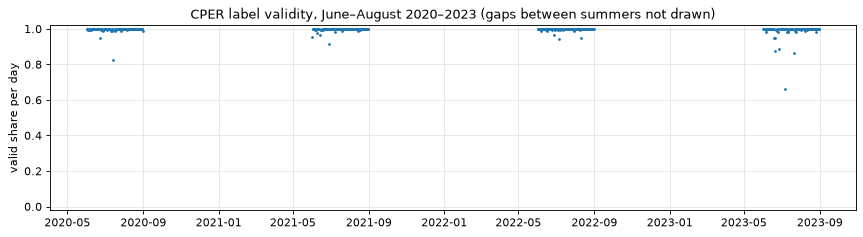

In [4]:
fig, ax = plt.subplots(figsize=(13, 3))
v = pd.concat([s.valid.resample('1D').mean() for s in L.values()])
ax.plot(v.index, v.to_numpy(), '.', ms=3)
ax.set(ylabel='valid share per day', title='CPER label validity, June–August 2020–2023 (gaps between summers not drawn)', ylim=(-.02, 1.02));

## 3 · Diurnal cycle of D by month: clock time vs solar time

The mean D_h by local clock hour for each month (valid rows, all 24 hours, so that the dawn minimum is inside the window), the hour of the daily minimum, and the time D has risen half-way from its minimum to its maximum (the *morning half-rise*), compared with sunrise. If the diurnal cycle were fixed in clock time, the curves would differ only by an offset. If it follows the sun, its shape and the timing of the minimum shift with sunrise, which is the structure a clock-only context cannot represent (notebook 11, V-N9).

slope of the morning half-rise on sunrise across 12 months: -0.26 (0 = fixed in clock time, 1 = follows the sun; 30-min bins)


,sunrise,sunset,D_min_hour,D_half_rise,D_max_hour,amplitude,rise_after_sunrise
month,,,,,,,
2020-06,4.450,19.532,4.0,8.0,14.5,16.716,3.550
2020-07,4.675,19.478,4.0,8.5,15.0,17.914,3.825
2020-08,5.161,18.947,1.5,8.5,13.5,17.522,3.339
2021-06,4.450,19.523,5.0,9.0,16.0,13.836,4.550
2021-07,4.666,19.487,5.0,9.0,14.5,13.458,4.334
2021-08,5.143,18.974,5.5,9.0,15.5,14.869,3.857
2022-06,4.450,19.523,4.5,9.0,16.5,14.994,4.550
2022-07,4.666,19.487,3.5,8.5,13.0,13.581,3.834
2022-08,5.143,18.974,4.5,8.5,13.5,13.706,3.357


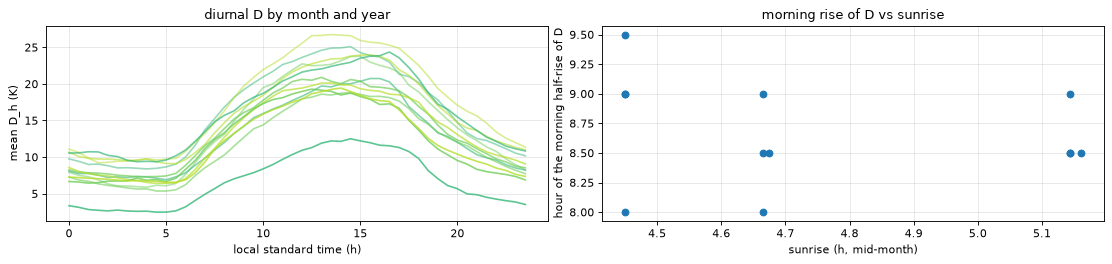

In [5]:
rows = []
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
for k, s in L.items():
    s = s[s.valid]
    loc = s.index + pd.Timedelta(hours=OFF)
    h = loc.hour + loc.minute / 60
    prof = s.D_h.groupby(np.floor(h * 2) / 2).mean()
    ax[0].plot(prof.index, prof.to_numpy(), label=k, color=plt.cm.viridis(int(k[5:7]) / 9), alpha=.5 + .1 * (int(k[:4]) - 2020))
    h_grid = np.linspace(3, 21, 2000)
    g = data.solar(np.full_like(h_grid, pd.Timestamp(f'{k}-15').day_of_year), h_grid, LAT, LON, OFF)
    up = h_grid[g.solar_elev_deg.to_numpy() > -0.83]
    lo, hi = prof.min(), prof.max()
    rise = prof.index[(prof.index > prof.idxmin()) & (prof.index < prof.idxmax()) & (prof.to_numpy() >= lo + .5 * (hi - lo))].min()  # morning half-rise
    rows.append(dict(month=k, sunrise=up[0], sunset=up[-1], D_min_hour=prof.idxmin(), D_half_rise=rise, D_max_hour=prof.idxmax(), amplitude=hi - lo))
ax[0].set(xlabel='local standard time (h)', ylabel='mean D_h (K)', title='diurnal D by month and year')
cyc = pd.DataFrame(rows).set_index('month').assign(rise_after_sunrise=lambda d: d.D_half_rise - d.sunrise)
ax[1].plot(cyc.sunrise, cyc.D_half_rise, 'o'); ax[1].set(xlabel='sunrise (h, mid-month)', ylabel='hour of the morning half-rise of D', title='morning rise of D vs sunrise')
slope = np.polyfit(cyc.sunrise, cyc.D_half_rise, 1)[0]
print(f'slope of the morning half-rise on sunrise across 12 months: {slope:.2f} (0 = fixed in clock time, 1 = follows the sun; 30-min bins)')
fig.tight_layout()
cyc

## 4 · Frozen image regions on one midday frame per season

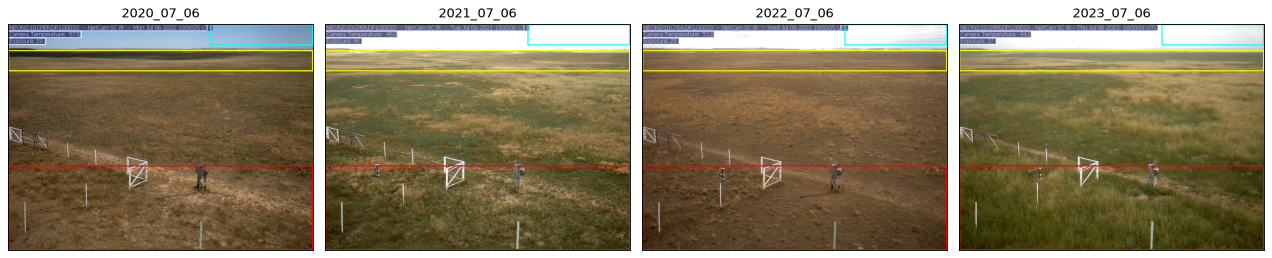

In [6]:
mid = sorted((neon.RAW / 'phenocam' / CAM / 'midday').glob('*.jpg'))
pick = {y: next(p for p in mid if f'_{y}_07_' in p.name) for y in YEARS}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax_, (y, p) in zip(axes, pick.items()):
    im = Image.open(p).convert('RGB')
    dr = ImageDraw.Draw(im)
    for name, box in features.REGIONS[SITE].items(): dr.rectangle(box, outline={'sky': 'cyan', 'far': 'yellow', 'near': 'red'}[name], width=5)
    for box in features.OVERLAY: dr.rectangle(box, outline='white', width=3)
    ax_.imshow(im.reduce(2)); ax_.set(title=p.name[24:34], xticks=[], yticks=[])
fig.tight_layout()

## 5 · Hourly frame inventory and camera state, 2020–2022 (no JPEG)

Day listings come from the PhenoCam browse pages, and only the `.meta` files of hourly frames (on the hour, 06–19 LST) are fetched. 2023 was verified in notebook 09.

In [7]:
def listing(month):
    d = neon.RAW / 'phenocam' / CAM / month
    f = d / 'listing.csv'
    if not f.exists():
        d.mkdir(parents=True, exist_ok=True)
        days = pd.date_range(f'{month}-01', periods=pd.Period(month).days_in_month)
        with ThreadPoolExecutor(2) as ex: names = list(ex.map(lambda day: neon.camera_day(CAM, day), days))
        pd.DataFrame([(day.date(), b) for day, bs in zip(days, names) for b in bs], columns=['day', 'base']).to_csv(f, index=False)
    return pd.read_csv(f)

MONTHS_IMG = [f'{y}-{m}' for y in range(2020, 2023) for m in MONTHS]
for m in MONTHS_IMG: listing(m)
F = neon.load_frames(CAM, MONTHS_IMG, OFF)
hourly = (F.base.str[-4:-2] == '00') & F.base.str[-6:-4].astype(int).between(6, 19)
todo = F[hourly & ~F.base.map(lambda b: (neon.RAW / 'phenocam' / CAM / f'{b[-17:-13]}-{b[-12:-10]}' / f'{b}.meta').exists())]
with ThreadPoolExecutor(2) as ex:
    list(ex.map(lambda b: neon.fetch(neon.archive_url(CAM, b, 'meta'), neon.RAW / 'phenocam' / CAM / f'{b[-17:-13]}-{b[-12:-10]}' / f'{b}.meta', missing_ok=True), todo.base))
F = neon.load_frames(CAM, MONTHS_IMG, OFF)
H = F[(F.base.str[-4:-2] == '00') & F.base.str[-6:-4].astype(int).between(6, 19)]
H = H.assign(offset_s=(pd.to_datetime(H.overlay_utc, utc=True) - H.utc).dt.total_seconds().abs())  # frames without .meta give NaT
inv = H.groupby('month').agg(hourly_listed=('base', 'size'), meta=('overlay_utc', lambda x: x.notna().mean()), max_clock_offset_s=('offset_s', 'max'),
                             **{f'distinct_{k}': (k, 'nunique') for k in ['auto_haze', 'agc', 'auto_exposure', 'wb', 'resolution', 'ir_enable', 'overlay_pos']})
inv

,hourly_listed,meta,max_clock_offset_s,distinct_auto_haze,distinct_agc,distinct_auto_exposure,distinct_wb,distinct_resolution,distinct_ir_enable,distinct_overlay_pos
month,,,,,,,,,,
2020-06,419,0.0,NaN,1,1,1,1,1,1,1
2020-07,427,0.0,NaN,1,1,1,1,1,1,1
2020-08,432,0.0,NaN,1,1,1,1,1,1,1
2021-06,419,0.0,NaN,1,1,1,1,1,1,1
2021-07,433,0.0,NaN,1,1,1,1,1,1,1
2021-08,377,0.0,NaN,1,1,1,1,1,1,1
2022-06,420,0.0,NaN,1,1,1,1,1,1,1
2022-07,433,0.0,NaN,1,1,1,1,1,1,1
2022-08,432,0.0,NaN,1,1,1,1,1,1,1


In [8]:
def overlay_kind(b):
    f = neon.RAW / 'phenocam' / CAM / f'{b[-17:-13]}-{b[-12:-10]}' / f'{b}.meta'
    if not f.exists(): return 'no .meta'
    o = neon.parse_meta(f.read_text(errors='replace')).get('overlay_text', '')
    return 'template (%H:%M:%S)' if '%H' in o else 'rendered time' if 'UTC' in o else 'other'

print(H.assign(kind=H.base.map(overlay_kind)).groupby(['month', 'kind']).size().unstack(fill_value=0))

kind     no .meta  template (%H:%M:%S)
month                                 
2020-06         0                  419
2020-07         0                  427
2020-08         0                  432
2021-06         0                  419
2021-07         0                  433
2021-08         0                  377
2022-06         0                  420
2022-07         0                  433
2022-08        13                  419


In [9]:
print('configuration values seen (2020–2022 hourly frames):', {k: sorted(H[k].dropna().unique().tolist()) for k in ['auto_haze', 'agc', 'auto_exposure', 'wb', 'resolution', 'ir_enable', 'overlay_pos']})
days = H.assign(d=H.utc.dt.floor('D')).groupby(['month', 'd']).size()
print('days with fewer than 12 hourly frames:', days[days < 12].groupby(level=0).size().to_dict())

configuration values seen (2020–2022 hourly frames): {'auto_haze': ['1'], 'agc': ['1'], 'auto_exposure': ['1'], 'wb': ['385/256/330'], 'resolution': ['6'], 'ir_enable': ['0'], 'overlay_pos': ['0/0/0']}
days with fewer than 12 hourly frames: {'2020-06': 2, '2020-07': 3, '2020-08': 2, '2021-06': 2, '2021-07': 2, '2021-08': 4, '2022-06': 2, '2022-07': 2, '2022-08': 2}


**Reading.**
1. **Inventory.** All five products are published for every June–August month of 2020–2025. Summers 2024 and 2025 therefore exist as genuinely untouched years and stay reserved (plan §2); nothing of them was downloaded.
2. **Labels** (2020–2023, all twelve months).
   - The valid share is ≥ 0.98 in every month; inconsistent minutes are 0–15 per month, except June–July 2023 (300 and 659, the wetting episodes of notebook 08).
   - The HMP155 expanded RH uncertainty is constant within each year but changes between years: 1.18 % (2020), 1.50 % (2021), 3.09 % (2022) and 2.48 % (2023). σ(D_h) follows it (0.17–0.30 K). This is consistent with a per-year calibration state, and it is one reason years are folds rather than pooled.
   - No month blanks RH at high implied RH except July 2023 (2 %).
   - The radiation error in calm, high sun is 1.06–1.80 K in every month. Unlike HARV 2022 (notebook 13), CPER shows no anomalous year.
3. **Diurnal cycle of D.**
   - Its amplitude ranges from 10 to 18 K and differs more between years than between months.
   - The morning half-rise falls 3.3–5.1 h after sunrise, at 08:00–09:30 LST. Its slope on sunrise across the 12 months is −0.26, so it does not follow the sun.
   - Sunrise moves by only 0.7 h over June–August, and the profile has 30-min bins, so this test is weak. It provides no evidence that CPER needs the solar context, and none that it does not.
   - The solar candidates of notebook 14 therefore remain candidates, chosen by training-only selection, not assumptions.
4. **Image regions.** The frozen sky, far and near bands sit on the same scene features in all four seasons (horizon band, far grassland, near field with the fence and gate). No region changes are needed.
5. **Frames and camera state, 2020–2022.**
   - There are 3,792 hourly frames listed, 13 of them without `.meta` on the server.
   - The configuration is identical in every frame that has a `.meta`: auto-haze, AGC and auto-exposure on, white balance 385/256/330, resolution 6, IR off, overlay at 0/0/0.
   - August 2021 has fewer frames (377 of ~434; four days under 12 frames); 2–3 days per other month are short.
   - **The `.meta` overlay field holds the template, not the rendered time, in every 2020–2022 file.** The clock therefore cannot be verified from `.meta` for those years, as it was for 2023. This is recorded as a plan deviation (plan §9): the clock is to be checked on the burned-in overlay of the JPEGs.

**Status.** Plan steps 1–2 are done. The next step (3, the hourly JPEGs) waits until an inference protocol has passed validation (plan §7).